# Vision Transformer (ViT) on CIFAR-10 — Local, Resumable Research Notebook

This notebook is designed for **local Jupyter in Antigravity**. It reimplements a compact Vision Transformer (ViT) from scratch and compares it with a CIFAR-adapted ResNet-18. It also includes a 20%-data experiment, a dropout ablation, optional multi-seed dropout runs, learning curves, a consolidated results CSV, and attention rollout.

## Key safeguards against losing progress
- Model checkpoints are saved to disk **after every completed epoch**.
- Both the latest training state and best-validation model are saved.
- Training history is written to CSV after each epoch.
- If the kernel or IDE stops, rerun the notebook from the top and keep `RESUME_FROM_CHECKPOINT = True`.
- Checkpoints and results live in `vit_cifar10_artifacts/` beside the notebook; do not delete that folder.
- Resume only with the same experiment name, model configuration, dataset split, and epoch budget. To start a new run or change the epoch budget, change the experiment name.

**Default model:** 32×32 input, patch size 4, embedding dimension 128, 4 attention heads, 6 Transformer blocks, MLP dimension 512, AdamW, 15 epochs.

**Local performance:** the notebook automatically selects CUDA, Apple Silicon MPS, or CPU. On an 8 GB Mac, begin with `BATCH_SIZE = 64` and `NUM_WORKERS = 0`. CPU training can be slow. The full comparison includes several training runs; use the run switches to control what executes.

**Scientific note:** CIFAR-10 and a small model are a reduced-scale reproduction, not a direct reproduction of the original ViT paper's large-scale ImageNet/JFT results. Attention rollout is a qualitative visualization, not proof of causal feature importance.

## 1. Environment and persistent artifact folders
Run this cell first. Install dependencies in the same Python environment that your Antigravity Jupyter kernel uses.

In [1]:
import os
import sys
import json
import time
import copy
import random
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

SEED = 42
PROJECT_DIR = Path.cwd()
ARTIFACT_DIR = PROJECT_DIR / "vit_cifar10_artifacts"
CHECKPOINT_DIR = ARTIFACT_DIR / "checkpoints"
RESULTS_DIR = ARTIFACT_DIR / "results"
DATA_DIR = ARTIFACT_DIR / "data"

for folder in (ARTIFACT_DIR, CHECKPOINT_DIR, RESULTS_DIR, DATA_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("Project directory:", PROJECT_DIR)
print("Persistent artifacts:", ARTIFACT_DIR.resolve())

Matplotlib is building the font cache; this may take a moment.


Python: 3.14.6
Platform: macOS-26.6.2-arm64-arm-64bit-Mach-O
PyTorch: 2.14.1
Torchvision: 0.29.1
Device: mps
Project directory: /Users/adityakumarjha/Documents/lab/ViT_CIFAR10_Local_Jupyter_Bundle
Persistent artifacts: /Users/adityakumarjha/Documents/lab/ViT_CIFAR10_Local_Jupyter_Bundle/vit_cifar10_artifacts


## 2. Experiment controls
Change these values before starting a run. The main runs are enabled; the six-run multi-seed ablation is optional because it can take a long time on a laptop.

In [2]:
# Core training configuration
EPOCHS = 15
BATCH_SIZE = 64
NUM_WORKERS = 0       # safest default for local Jupyter/Apple Silicon
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.05

# Resume from the last completed epoch checkpoint when one exists.
RESUME_FROM_CHECKPOINT = True

# Run switches
RUN_VIT_BASELINE = True
RUN_RESNET18 = True
RUN_LOW_DATA_VIT = True
RUN_SINGLE_DROPOUT_ABLATION = True

# Optional: 2 dropout settings × 3 seeds = 6 additional training runs.
# Turn on only when you have time for the full controlled ablation.
RUN_MULTI_SEED_DROPOUT = False
DROPOUT_SEEDS = [42, 123, 2026]
DROPOUT_VALUES = [0.0, 0.1]

# ViT architecture
MODEL_CONFIG = {
    "img_size": 32,
    "patch_size": 4,
    "num_classes": 10,
    "embed_dim": 128,
    "num_heads": 4,
    "depth": 6,
    "mlp_dim": 512,
    "dropout": 0.1,
}

print("Epochs per run:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Multi-seed dropout enabled:", RUN_MULTI_SEED_DROPOUT)

Epochs per run: 15
Batch size: 64
Multi-seed dropout enabled: False


## 3. Reproducibility and checkpoint utilities
Each experiment gets its own checkpoint names. The `last` checkpoint is written every epoch; the `best` checkpoint is selected using validation accuracy.

In [3]:
def capture_rng_state():
    state = {
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["cuda_rng_state_all"] = torch.cuda.get_rng_state_all()
    return state

def restore_rng_state(state):
    if not state:
        return
    if "python_rng_state" in state:
        random.setstate(state["python_rng_state"])
    if "numpy_rng_state" in state:
        np.random.set_state(state["numpy_rng_state"])
    if "torch_rng_state" in state:
        torch.set_rng_state(state["torch_rng_state"].cpu())
    if torch.cuda.is_available() and "cuda_rng_state_all" in state:
        torch.cuda.set_rng_state_all(state["cuda_rng_state_all"])

def safe_torch_load(path):
    # weights_only=False is required for trusted local checkpoints with metadata.
    # Only load checkpoints you created yourself.
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def experiment_paths(name):
    safe_name = "".join(c if c.isalnum() or c in "-_." else "_" for c in name)
    return {
        "last": CHECKPOINT_DIR / f"{safe_name}_last.pth",
        "best": CHECKPOINT_DIR / f"{safe_name}_best.pth",
        "history": RESULTS_DIR / f"{safe_name}_history.csv",
        "metadata": RESULTS_DIR / f"{safe_name}_metadata.json",
    }

print("Checkpoint directory:", CHECKPOINT_DIR.resolve())

Checkpoint directory: /Users/adityakumarjha/Documents/lab/ViT_CIFAR10_Local_Jupyter_Bundle/vit_cifar10_artifacts/checkpoints


## 4. Implement patch embedding and Transformer components
The core ViT is implemented directly with PyTorch modules.

In [4]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=128):
        super().__init__()
        if img_size % patch_size != 0:
            raise ValueError("img_size must be divisible by patch_size.")
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.projection = nn.Conv2d(
            in_channels, embed_dim,
            kernel_size=patch_size, stride=patch_size
        )

    def forward(self, x):
        # (B, C, H, W) -> (B, embed_dim, grid_h, grid_w)
        x = self.projection(x)
        # Flatten patches and put token dimension before embedding dimension.
        return x.flatten(2).transpose(1, 2)


class ViTEmbeddings(nn.Module):
    def __init__(self, embed_dim=128, num_patches=64, dropout=0.1):
        super().__init__()
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.position_embeddings = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )
        self.dropout = nn.Dropout(dropout)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.position_embeddings, std=0.02)

    def forward(self, patch_tokens):
        batch_size = patch_tokens.shape[0]
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        tokens = torch.cat((cls_tokens, patch_tokens), dim=1)
        return self.dropout(tokens + self.position_embeddings)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, dropout=0.1):
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError("embed_dim must be divisible by num_heads.")
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.projection = nn.Linear(embed_dim, embed_dim)
        self.attention_dropout = nn.Dropout(dropout)
        self.projection_dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        batch_size, tokens, embed_dim = x.shape
        qkv = self.qkv(x).reshape(
            batch_size, tokens, 3, self.num_heads, self.head_dim
        ).permute(2, 0, 3, 1, 4)
        query, key, value = qkv.unbind(0)
        scores = (query @ key.transpose(-2, -1)) * self.scale
        attention = scores.softmax(dim=-1)
        used_attention = self.attention_dropout(attention)
        output = used_attention @ value
        output = output.transpose(1, 2).reshape(batch_size, tokens, embed_dim)
        output = self.projection_dropout(self.projection(output))
        if return_attention:
            return output, attention
        return output


class MLP(nn.Module):
    def __init__(self, embed_dim=128, mlp_dim=512, dropout=0.1):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.layers(x)


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, mlp_dim=512, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attention = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLP(embed_dim, mlp_dim, dropout)

    def forward(self, x, return_attention=False):
        if return_attention:
            attention_output, attention = self.attention(
                self.norm1(x), return_attention=True
            )
        else:
            attention_output = self.attention(self.norm1(x))
        x = x + attention_output
        x = x + self.mlp(self.norm2(x))
        if return_attention:
            return x, attention
        return x


class VisionTransformer(nn.Module):
    def __init__(
        self, img_size=32, patch_size=4, in_channels=3, num_classes=10,
        embed_dim=128, num_heads=4, depth=6, mlp_dim=512, dropout=0.1
    ):
        super().__init__()
        self.patch_embedding = PatchEmbedding(
            img_size, patch_size, in_channels, embed_dim
        )
        self.token_embedding = ViTEmbeddings(
            embed_dim, self.patch_embedding.num_patches, dropout
        )
        self.encoder_blocks = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, mlp_dim, dropout)
            for _ in range(depth)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)
        self.config = {
            "img_size": img_size, "patch_size": patch_size,
            "in_channels": in_channels, "num_classes": num_classes,
            "embed_dim": embed_dim, "num_heads": num_heads,
            "depth": depth, "mlp_dim": mlp_dim, "dropout": dropout,
        }

    def forward(self, x, return_attention=False):
        tokens = self.patch_embedding(x)
        x = self.token_embedding(tokens)
        attention_layers = []
        for block in self.encoder_blocks:
            if return_attention:
                x, attention = block(x, return_attention=True)
                attention_layers.append(attention)
            else:
                x = block(x)
        x = self.final_norm(x)
        logits = self.classifier(x[:, 0])
        if return_attention:
            return logits, attention_layers
        return logits

# Architecture sanity check
test_model = VisionTransformer(**MODEL_CONFIG).to(device)
with torch.no_grad():
    test_logits = test_model(torch.randn(2, 3, 32, 32, device=device))
print("Sanity-check logits shape:", tuple(test_logits.shape))
print("ViT trainable parameters:", f"{count_parameters(test_model):,}")
del test_model

Sanity-check logits shape: (2, 10)
ViT trainable parameters: 1,205,898


## 5. Download and prepare CIFAR-10
The training and validation partitions are fixed at 45,000 and 5,000 images. Training uses random crop and horizontal flip; validation and test use deterministic preprocessing.

In [13]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_aug_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=train_transform
)
train_eval_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=eval_transform
)
test_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=eval_transform
)

split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(50000, generator=split_generator).tolist()
train_indices = permutation[:45000]
val_indices = permutation[45000:]

from torch.utils.data import DataLoader, Subset

train_dataset = Subset(train_aug_dataset, train_indices)
val_dataset = Subset(train_eval_dataset, val_indices)
classes = train_aug_dataset.classes

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(dataset, shuffle=False, seed=SEED, batch_size=BATCH_SIZE):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda"),
        worker_init_fn=seed_worker,
        generator=generator,
        persistent_workers=(NUM_WORKERS > 0),
    )

train_loader = make_loader(train_dataset, shuffle=True, seed=SEED + 1)
val_loader = make_loader(val_dataset, shuffle=False, seed=SEED + 2)
test_loader = make_loader(test_dataset, shuffle=False, seed=SEED + 3)

print("Classes:", classes)
print(f"Train: {len(train_dataset):,} | Validation: {len(val_dataset):,} | Test: {len(test_dataset):,}")
print(f"Batches: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")

100.0%


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 45,000 | Validation: 5,000 | Test: 10,000
Batches: train=704, val=79, test=157


## 6. Training, validation, and crash-safe checkpointing
Checkpoints are saved after each completed epoch. If the process stops mid-epoch, restarting resumes from the most recent completed epoch. Set `RESUME_FROM_CHECKPOINT = False` only when you intentionally want to overwrite/restart a named experiment.

In [14]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        n = labels.size(0)
        loss_sum += loss.item() * n
        correct += (logits.argmax(1) == labels).sum().item()
        count += n
    return loss_sum / count, correct / count


@torch.no_grad()
def evaluate_classifier(model, loader, criterion):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        n = labels.size(0)
        loss_sum += loss.item() * n
        correct += (logits.argmax(1) == labels).sum().item()
        count += n
    return loss_sum / count, correct / count


def write_history(history, path):
    pd.DataFrame(history).to_csv(path, index=False)


def fit_experiment(
    name, model, train_dl, val_dl, test_dl, epochs=EPOCHS,
    lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
    model_config=None, resume=RESUME_FROM_CHECKPOINT
):
    paths = experiment_paths(name)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {
        "epoch": [], "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "learning_rate": [], "epoch_seconds": []
    }
    start_epoch = 0
    best_val_acc = -1.0
    best_epoch = 0

    if resume and paths["last"].exists():
        checkpoint = safe_torch_load(paths["last"])
        if checkpoint.get("experiment") != name:
            raise ValueError("Checkpoint experiment name mismatch.")
        if checkpoint.get("model_config") != model_config:
            raise ValueError(
                f"Checkpoint config mismatch for {name}. Use a new experiment name "
                "if you changed the model configuration."
            )
        if checkpoint.get("epochs") != epochs:
            raise ValueError(
                f"Checkpoint was created for {checkpoint.get('epochs')} epochs, "
                f"but this run requests {epochs}. Keep the same epoch budget to resume, "
                "or change the experiment name to start a new run."
            )
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        history = checkpoint["history"]
        start_epoch = int(checkpoint["completed_epoch"])
        best_val_acc = float(checkpoint["best_val_acc"])
        best_epoch = int(checkpoint["best_epoch"])
        restore_rng_state(checkpoint.get("rng_state"))
        print(f"Resuming {name} at epoch {start_epoch + 1}/{epochs}.")

    for epoch in range(start_epoch, epochs):
        epoch_start = time.time()
        train_loss, train_acc = train_one_epoch(model, train_dl, optimizer, criterion)
        val_loss, val_acc = evaluate_classifier(model, val_dl, criterion)
        used_lr = optimizer.param_groups[0]["lr"]
        duration = time.time() - epoch_start

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["learning_rate"].append(used_lr)
        history["epoch_seconds"].append(duration)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            torch.save({
                "experiment": name,
                "epoch": best_epoch,
                "model_config": model_config,
                "model_state_dict": model.state_dict(),
                "best_val_acc": best_val_acc,
            }, paths["best"])

        scheduler.step()

        # Save the latest full training state after every epoch.
        torch.save({
            "experiment": name,
            "completed_epoch": epoch + 1,
            "epochs": epochs,
            "model_config": model_config,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "history": history,
            "best_val_acc": best_val_acc,
            "best_epoch": best_epoch,
            "rng_state": capture_rng_state(),
        }, paths["last"])
        write_history(history, paths["history"])

        print(
            f"{name} | {epoch+1:02d}/{epochs} | "
            f"train acc {train_acc*100:.2f}% | val acc {val_acc*100:.2f}% | "
            f"val loss {val_loss:.4f} | {duration:.1f}s"
        )

    if not paths["best"].exists():
        raise RuntimeError(f"No best checkpoint was created for {name}.")
    best_checkpoint = safe_torch_load(paths["best"])
    model.load_state_dict(best_checkpoint["model_state_dict"])
    test_loss, test_acc = evaluate_classifier(model, test_dl, criterion)

    result = {
        "experiment": name,
        "parameters": count_parameters(model),
        "epochs": epochs,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_acc,
        "test_accuracy": test_acc,
        "test_loss": test_loss,
        "best_checkpoint": str(paths["best"]),
        "last_checkpoint": str(paths["last"]),
        "history": history,
    }
    with open(paths["metadata"], "w", encoding="utf-8") as f:
        json.dump({k: v for k, v in result.items() if k != "history"}, f, indent=2)
    print(
        f"\n{name} complete | best val={best_val_acc*100:.2f}% "
        f"(epoch {best_epoch}) | test={test_acc*100:.2f}% "
        f"| parameters={count_parameters(model):,}"
    )
    return result

print("Training functions ready.")

Training functions ready.


## 7. Train the baseline ViT
This is the main from-scratch model. The run can be resumed from its last checkpoint if the notebook kernel restarts.

In [15]:
baseline_result = None
baseline_model = None

if RUN_VIT_BASELINE:
    seed_everything(SEED)
    baseline_model = VisionTransformer(**MODEL_CONFIG).to(device)
    baseline_result = fit_experiment(
        name="vit_baseline",
        model=baseline_model,
        train_dl=make_loader(train_dataset, shuffle=True, seed=SEED + 11),
        val_dl=make_loader(val_dataset, shuffle=False, seed=SEED + 12),
        test_dl=make_loader(test_dataset, shuffle=False, seed=SEED + 13),
        epochs=EPOCHS,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        model_config=MODEL_CONFIG,
    )
else:
    print("Baseline ViT skipped by configuration.")

vit_baseline | 01/15 | train acc 32.65% | val acc 40.86% | val loss 1.6193 | 53.8s
vit_baseline | 02/15 | train acc 44.34% | val acc 50.40% | val loss 1.3542 | 49.3s
vit_baseline | 03/15 | train acc 50.28% | val acc 53.56% | val loss 1.2977 | 48.4s
vit_baseline | 04/15 | train acc 54.29% | val acc 58.28% | val loss 1.1362 | 48.4s
vit_baseline | 05/15 | train acc 57.13% | val acc 59.60% | val loss 1.1090 | 48.9s
vit_baseline | 06/15 | train acc 59.34% | val acc 63.16% | val loss 1.0248 | 48.5s
vit_baseline | 07/15 | train acc 61.66% | val acc 65.36% | val loss 0.9757 | 48.4s
vit_baseline | 08/15 | train acc 63.67% | val acc 66.34% | val loss 0.9267 | 53.3s
vit_baseline | 09/15 | train acc 65.54% | val acc 67.68% | val loss 0.9008 | 59.3s
vit_baseline | 10/15 | train acc 67.23% | val acc 69.36% | val loss 0.8618 | 55.4s
vit_baseline | 11/15 | train acc 68.56% | val acc 70.88% | val loss 0.8283 | 49.5s
vit_baseline | 12/15 | train acc 69.89% | val acc 71.08% | val loss 0.8279 | 49.3s
vit_

## 8. Plot ViT learning curves

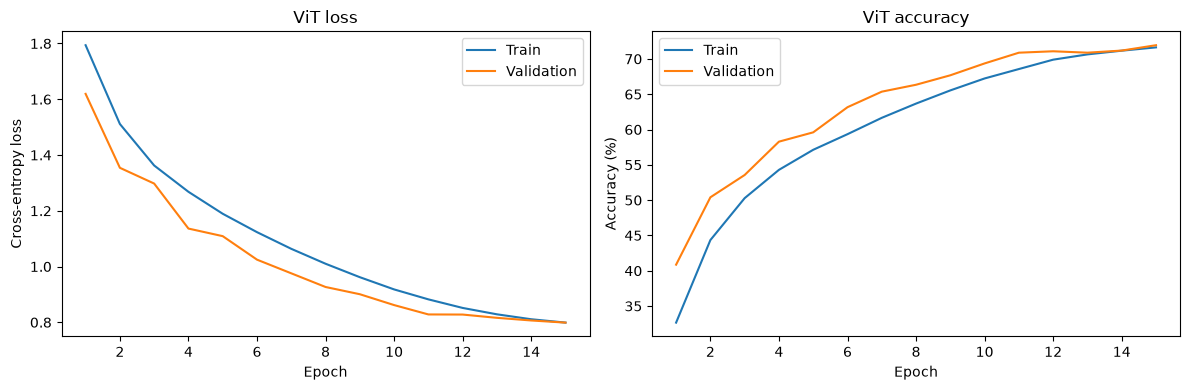

In [16]:
if baseline_result is not None:
    h = baseline_result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["epoch"], h["train_loss"], label="Train")
    axes[0].plot(h["epoch"], h["val_loss"], label="Validation")
    axes[0].set_title("ViT loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()
    axes[1].plot(h["epoch"], np.array(h["train_acc"]) * 100, label="Train")
    axes[1].plot(h["epoch"], np.array(h["val_acc"]) * 100, label="Validation")
    axes[1].set_title("ViT accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("Run the baseline ViT to plot learning curves.")

## 9. Experiment: ResNet-18 trained from scratch
The ResNet stem is adapted for 32×32 CIFAR images (3×3 stride 1 convolution and no initial max-pooling).

In [17]:
def build_cifar_resnet18(num_classes=10):
    resnet = torchvision.models.resnet18(weights=None)
    resnet.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    resnet.maxpool = nn.Identity()
    resnet.fc = nn.Linear(resnet.fc.in_features, num_classes)
    return resnet

resnet_result = None
if RUN_RESNET18:
    seed_everything(SEED + 100)
    resnet_model = build_cifar_resnet18().to(device)
    resnet_config = {
        "architecture": "CIFAR-adapted ResNet-18",
        "weights": None,
        "num_classes": 10,
    }
    resnet_result = fit_experiment(
        name="resnet18_scratch",
        model=resnet_model,
        train_dl=make_loader(train_dataset, shuffle=True, seed=SEED + 101),
        val_dl=make_loader(val_dataset, shuffle=False, seed=SEED + 102),
        test_dl=make_loader(test_dataset, shuffle=False, seed=SEED + 103),
        epochs=EPOCHS,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        model_config=resnet_config,
    )
else:
    print("ResNet-18 experiment skipped.")

resnet18_scratch | 01/15 | train acc 49.71% | val acc 61.10% | val loss 1.1368 | 140.1s
resnet18_scratch | 02/15 | train acc 66.83% | val acc 69.50% | val loss 0.9119 | 136.2s
resnet18_scratch | 03/15 | train acc 74.78% | val acc 76.18% | val loss 0.6921 | 139.4s
resnet18_scratch | 04/15 | train acc 78.57% | val acc 78.04% | val loss 0.6409 | 145.2s
resnet18_scratch | 05/15 | train acc 81.41% | val acc 79.48% | val loss 0.6146 | 122.9s
resnet18_scratch | 06/15 | train acc 83.66% | val acc 83.74% | val loss 0.4815 | 122.6s
resnet18_scratch | 07/15 | train acc 85.63% | val acc 84.72% | val loss 0.4621 | 125.8s
resnet18_scratch | 08/15 | train acc 87.28% | val acc 85.10% | val loss 0.4415 | 123.3s
resnet18_scratch | 09/15 | train acc 88.63% | val acc 87.00% | val loss 0.3692 | 122.5s
resnet18_scratch | 10/15 | train acc 90.27% | val acc 88.34% | val loss 0.3470 | 125.7s
resnet18_scratch | 11/15 | train acc 91.28% | val acc 88.36% | val loss 0.3333 | 126.6s
resnet18_scratch | 12/15 | train

## 10. Experiment: ViT with 20% of the training partition
This uses 9,000 images from the 45,000-image training partition. The validation and test sets remain unchanged.

In [18]:
low_data_result = None
if RUN_LOW_DATA_VIT:
    low_fraction = 0.20
    low_count = int(len(train_dataset) * low_fraction)
    low_gen = torch.Generator().manual_seed(SEED + 200)
    low_positions = torch.randperm(len(train_dataset), generator=low_gen)[:low_count].tolist()
    low_data_dataset = Subset(train_dataset, low_positions)

    seed_everything(SEED + 204)
    low_data_model = VisionTransformer(**MODEL_CONFIG).to(device)
    low_data_result = fit_experiment(
        name="vit_low_data_20pct",
        model=low_data_model,
        train_dl=make_loader(low_data_dataset, shuffle=True, seed=SEED + 201),
        val_dl=make_loader(val_dataset, shuffle=False, seed=SEED + 202),
        test_dl=make_loader(test_dataset, shuffle=False, seed=SEED + 203),
        epochs=EPOCHS,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        model_config=MODEL_CONFIG,
    )
    print(f"Low-data subset: {low_count:,}/{len(train_dataset):,} images.")
else:
    print("Low-data experiment skipped.")

vit_low_data_20pct | 01/15 | train acc 24.10% | val acc 32.30% | val loss 1.8336 | 15.0s
vit_low_data_20pct | 02/15 | train acc 30.76% | val acc 33.62% | val loss 1.7615 | 14.4s
vit_low_data_20pct | 03/15 | train acc 33.99% | val acc 33.22% | val loss 1.8129 | 14.3s
vit_low_data_20pct | 04/15 | train acc 36.98% | val acc 34.86% | val loss 1.7511 | 14.3s
vit_low_data_20pct | 05/15 | train acc 39.41% | val acc 36.74% | val loss 1.7379 | 14.1s
vit_low_data_20pct | 06/15 | train acc 41.49% | val acc 42.84% | val loss 1.5581 | 14.3s
vit_low_data_20pct | 07/15 | train acc 43.78% | val acc 44.90% | val loss 1.5217 | 930.5s
vit_low_data_20pct | 08/15 | train acc 45.79% | val acc 46.62% | val loss 1.4795 | 814.3s
vit_low_data_20pct | 09/15 | train acc 47.18% | val acc 46.62% | val loss 1.4958 | 12.2s
vit_low_data_20pct | 10/15 | train acc 49.19% | val acc 49.64% | val loss 1.3830 | 12.2s
vit_low_data_20pct | 11/15 | train acc 50.58% | val acc 47.60% | val loss 1.4152 | 11.8s
vit_low_data_20pct 

## 11. Experiment: single-run dropout ablation
This changes only the ViT dropout from 0.1 to 0.0. Treat a single-run difference as preliminary; the multi-seed experiment below is the more reliable comparison.

In [19]:
dropout_result = None
if RUN_SINGLE_DROPOUT_ABLATION:
    dropout_config = dict(MODEL_CONFIG)
    dropout_config["dropout"] = 0.0
    seed_everything(SEED + 300)
    dropout_model = VisionTransformer(**dropout_config).to(device)
    dropout_result = fit_experiment(
        name="vit_dropout_0_single_seed",
        model=dropout_model,
        train_dl=make_loader(train_dataset, shuffle=True, seed=SEED + 301),
        val_dl=make_loader(val_dataset, shuffle=False, seed=SEED + 302),
        test_dl=make_loader(test_dataset, shuffle=False, seed=SEED + 303),
        epochs=EPOCHS,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        model_config=dropout_config,
    )
else:
    print("Single-run dropout ablation skipped.")

vit_dropout_0_single_seed | 01/15 | train acc 35.56% | val acc 45.78% | val loss 1.4773 | 45.6s
vit_dropout_0_single_seed | 02/15 | train acc 48.84% | val acc 54.46% | val loss 1.2753 | 44.7s
vit_dropout_0_single_seed | 03/15 | train acc 54.19% | val acc 56.14% | val loss 1.1873 | 45.4s
vit_dropout_0_single_seed | 04/15 | train acc 58.08% | val acc 58.22% | val loss 1.1514 | 44.6s
vit_dropout_0_single_seed | 05/15 | train acc 61.09% | val acc 61.84% | val loss 1.0441 | 44.8s
vit_dropout_0_single_seed | 06/15 | train acc 64.13% | val acc 64.22% | val loss 1.0005 | 44.7s
vit_dropout_0_single_seed | 07/15 | train acc 66.93% | val acc 66.52% | val loss 0.9164 | 44.6s
vit_dropout_0_single_seed | 08/15 | train acc 69.00% | val acc 69.20% | val loss 0.8537 | 44.7s
vit_dropout_0_single_seed | 09/15 | train acc 71.12% | val acc 69.56% | val loss 0.8498 | 44.7s
vit_dropout_0_single_seed | 10/15 | train acc 72.60% | val acc 71.86% | val loss 0.7980 | 45.8s
vit_dropout_0_single_seed | 11/15 | trai

## 12. Optional: controlled multi-seed dropout ablation
This runs dropout 0.0 and 0.1 under each of three seeds (six runs). Each run has its own resumable checkpoint. Keep `RUN_MULTI_SEED_DROPOUT = False` until you are ready to spend the extra compute.

In [20]:
multi_seed_dropout_results = []

if RUN_MULTI_SEED_DROPOUT:
    for seed in DROPOUT_SEEDS:
        for dropout_rate in DROPOUT_VALUES:
            run_name = f"vit_dropout_{dropout_rate}_seed_{seed}"
            config = dict(MODEL_CONFIG)
            config["dropout"] = dropout_rate
            seed_everything(seed)
            model_ms = VisionTransformer(**config).to(device)

            result = fit_experiment(
                name=run_name,
                model=model_ms,
                train_dl=make_loader(train_dataset, shuffle=True, seed=seed + 1),
                val_dl=make_loader(val_dataset, shuffle=False, seed=seed + 2),
                test_dl=make_loader(test_dataset, shuffle=False, seed=seed + 3),
                epochs=EPOCHS,
                lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY,
                model_config=config,
            )
            result["seed"] = seed
            result["dropout"] = dropout_rate
            multi_seed_dropout_results.append(result)
            del model_ms
            if device.type == "cuda":
                torch.cuda.empty_cache()
            elif device.type == "mps":
                torch.mps.empty_cache()

    ms_df = pd.DataFrame([{
        "Seed": r["seed"],
        "Dropout": r["dropout"],
        "Epochs": r["epochs"],
        "Best epoch": r["best_epoch"],
        "Best validation accuracy (%)": 100 * r["best_val_accuracy"],
        "Test accuracy (%)": 100 * r["test_accuracy"],
        "Test loss": r["test_loss"],
    } for r in multi_seed_dropout_results])
    display(ms_df)
    ms_df.to_csv(RESULTS_DIR / "dropout_multiseed_runs.csv", index=False)

    ms_summary = ms_df.groupby("Dropout").agg(
        Runs=("Seed", "count"),
        Mean_validation_accuracy=("Best validation accuracy (%)", "mean"),
        SD_validation_accuracy=("Best validation accuracy (%)", "std"),
        Mean_test_accuracy=("Test accuracy (%)", "mean"),
        SD_test_accuracy=("Test accuracy (%)", "std"),
        Mean_test_loss=("Test loss", "mean"),
        SD_test_loss=("Test loss", "std"),
    ).reset_index()
    display(ms_summary)
    ms_summary.to_csv(RESULTS_DIR / "dropout_multiseed_summary.csv", index=False)
else:
    print("Multi-seed dropout ablation disabled. Set RUN_MULTI_SEED_DROPOUT = True to run it.")

Multi-seed dropout ablation disabled. Set RUN_MULTI_SEED_DROPOUT = True to run it.


## 13. Consolidated results
This table includes experiments completed in the current kernel session. Per-experiment metadata and history CSV files are saved independently so they remain available after a kernel restart.

In [21]:
completed_results = [
    r for r in [baseline_result, resnet_result, low_data_result, dropout_result]
    if r is not None
]

def result_row(r):
    return {
        "Experiment": r["experiment"],
        "Parameters": r["parameters"],
        "Epochs": r["epochs"],
        "Best epoch": r["best_epoch"],
        "Best validation accuracy (%)": round(100 * r["best_val_accuracy"], 2),
        "Test accuracy (%)": round(100 * r["test_accuracy"], 2),
        "Test loss": round(r["test_loss"], 4),
        "Best checkpoint": r["best_checkpoint"],
    }

if completed_results:
    results_df = pd.DataFrame([result_row(r) for r in completed_results])
    display(results_df)
    results_df.to_csv(RESULTS_DIR / "comparison_results.csv", index=False)
    print("Saved:", RESULTS_DIR / "comparison_results.csv")
else:
    print("No experiments were run. Enable at least one run switch in Section 2.")

,Experiment,Parameters,Epochs,Best epoch,Best validation accuracy (%),Test accuracy (%),Test loss,Best checkpoint
0,vit_baseline,1205898,15,15,71.94,72.00,0.8000,/Users/adityakumarjha/Documents/lab/ViT_CIFAR1...
1,resnet18_scratch,11173962,15,14,90.34,89.41,0.3327,/Users/adityakumarjha/Documents/lab/ViT_CIFAR1...
2,vit_low_data_20pct,1205898,15,15,51.22,51.11,1.3566,/Users/adityakumarjha/Documents/lab/ViT_CIFAR1...
3,vit_dropout_0_single_seed,1205898,15,15,74.42,75.02,0.7197,/Users/adityakumarjha/Documents/lab/ViT_CIFAR1...


Saved: /Users/adityakumarjha/Documents/lab/ViT_CIFAR10_Local_Jupyter_Bundle/vit_cifar10_artifacts/results/comparison_results.csv


## 14. Attention rollout visualization
Attention rollout multiplies residual-aware attention matrices across Transformer layers. It is a qualitative visualization of token attention, not a causal explanation of the model's prediction.

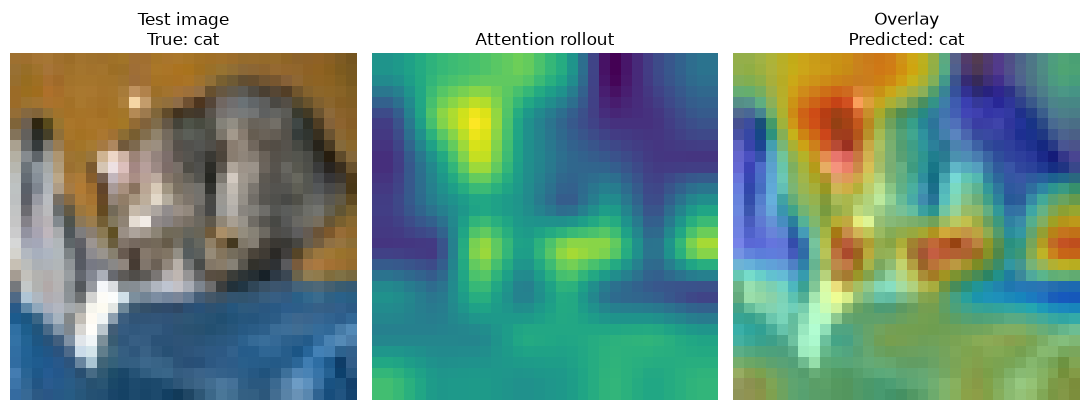

True class: cat
Predicted class: cat
Correct: True


In [22]:
@torch.no_grad()
def attention_rollout(attention_layers):
    # Each attention tensor has shape (B, heads, tokens, tokens).
    batch_size, _, token_count, _ = attention_layers[0].shape
    device_local = attention_layers[0].device
    identity = torch.eye(token_count, device=device_local).unsqueeze(0).expand(batch_size, -1, -1)
    joint_attention = identity
    for attention in attention_layers:
        mean_attention = attention.mean(dim=1)
        mean_attention = mean_attention + identity
        mean_attention = mean_attention / mean_attention.sum(dim=-1, keepdim=True)
        joint_attention = mean_attention @ joint_attention
    return joint_attention


if baseline_model is not None:
    baseline_best_path = experiment_paths("vit_baseline")["best"]
    baseline_ckpt = safe_torch_load(baseline_best_path)
    baseline_model.load_state_dict(baseline_ckpt["model_state_dict"])
    baseline_model.eval()

    image_batch, label_batch = next(iter(test_loader))
    image = image_batch[:1].to(device)
    true_label = int(label_batch[0].item())
    logits, attention_layers = baseline_model(image, return_attention=True)
    predicted_label = int(logits.argmax(dim=1).item())

    rollout = attention_rollout(attention_layers)
    patch_scores = rollout[0, 0, 1:]
    patch_side = MODEL_CONFIG["img_size"] // MODEL_CONFIG["patch_size"]
    patch_map = patch_scores.reshape(1, 1, patch_side, patch_side)
    heatmap = F.interpolate(
        patch_map, size=(32, 32), mode="bilinear", align_corners=False
    )[0, 0].detach().cpu().numpy()

    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)
    display_image = (image[0].detach().cpu() * std + mean).clamp(0, 1)
    display_image = display_image.permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(1, 3, figsize=(11, 4))
    axes[0].imshow(display_image)
    axes[0].set_title(f"Test image\nTrue: {classes[true_label]}")
    axes[0].axis("off")
    axes[1].imshow(heatmap, cmap="viridis")
    axes[1].set_title("Attention rollout")
    axes[1].axis("off")
    axes[2].imshow(display_image)
    axes[2].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[2].set_title(f"Overlay\nPredicted: {classes[predicted_label]}")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()

    print("True class:", classes[true_label])
    print("Predicted class:", classes[predicted_label])
    print("Correct:", predicted_label == true_label)
else:
    print("Enable and run the baseline ViT to generate attention rollout.")

## 15. Recovering progress after a crash

1. Keep the entire `vit_cifar10_artifacts/` directory. It contains checkpoints, per-epoch history CSVs, experiment metadata, and result tables.
2. Reopen this notebook in the same local Python environment.
3. Run cells from the top in order so the model classes, datasets, and functions are recreated.
4. Keep `RESUME_FROM_CHECKPOINT = True`.
5. Keep the same `EPOCHS`, experiment name, model config, data split, and training settings for a resumed run.
6. When the run finishes, the notebook loads the best-validation checkpoint and evaluates it on the test set.

**Important:** the notebook file itself does not automatically store every output until you save it. The training state is saved separately to disk. For backup, copy both this `.ipynb` and the complete `vit_cifar10_artifacts/` folder to another drive or repository.

## 16. Suggested interpretation for the report

- Compare ViT and ResNet-18 under the same data split and epoch budget, while noting their different parameter counts and inductive biases.
- Compare full-data and 20%-data ViT to measure sensitivity to training-set size.
- Treat the single-seed dropout comparison as exploratory. Use mean ± standard deviation from the optional multi-seed experiment for stronger evidence.
- Use validation accuracy for checkpoint selection; report test accuracy only as the final held-out metric.
- State that this compact CIFAR-10 experiment does not reproduce the original paper's scale or headline results.